In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Loading Dataset and A Sneak Preview

In [2]:
df=pd.read_csv("/kaggle/input/datasets/vedauv/what-makes-a-song-go-viral-10000-tracks/viral_songs.csv")

In [3]:
df.head()

,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
0,track_00001,Track_00001,Artist_1519,Pop,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,661412,1
1,track_00002,Track_00002,Artist_0458,Electronic,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1114175,1
2,track_00003,Track_00003,Artist_1386,Hip-Hop,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,105832,1
3,track_00004,Track_00004,Artist_0865,Classical,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,915397,0
4,track_00005,Track_00005,Artist_0192,Pop,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,3690733,1


In [4]:
rows,columns=df.shape
print(f"Number of rows in the dataset are : {rows}")
print(f"Number of columns in the dataset are : {columns}")

Number of rows in the dataset are : 10000
Number of columns in the dataset are : 17


In [5]:
df.isnull().sum()

track_id            0
track_name          0
artist              0
genre               0
release_year        0
duration_sec        0
danceability        0
energy              0
valence             0
tempo_bpm           0
acousticness        0
instrumentalness    0
speechiness         0
liveness            0
loudness_db         0
streams             0
viral               0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.dtypes

track_id             object
track_name           object
artist               object
genre                object
release_year          int64
duration_sec          int64
danceability        float64
energy              float64
valence             float64
tempo_bpm           float64
acousticness        float64
instrumentalness    float64
speechiness         float64
liveness            float64
loudness_db         float64
streams               int64
viral                 int64
dtype: object

## 🎵 Feature Dictionary

<div style="font-family: 'Trebuchet MS', sans-serif; font-size: 14px; line-height: 1.8;">

| **Feature** | **Description** |
|:---|:---|
| `track_id` | Unique identifier assigned to each track. |
| `track_name` | Title of the song. |
| `artist` | Name of the singer or music artist. |
| `genre` | Musical category or style of the song. |
| `release_year` | Year the song was released. |
| `duration_sec` | Duration of the song in seconds. |
| `danceability` | Measures how suitable a song is for dancing. |
| `energy` | Measures the intensity and activity level of the song. |
| `valence` | Measures the positivity or happiness conveyed by the music. |
| `tempo_bpm` | Speed of the beat in beats per minute (BPM). |
| `acousticness` | Estimates how acoustic the song sounds. |
| `instrumentalness` | Estimates whether the song contains vocals or is primarily instrumental. |
| `speechiness` | Measures the presence of spoken words in the song. |
| `liveness` | Estimates the likelihood of a live performance recording. |
| `loudness_db` | Overall loudness of the song in decibels (dB). |
| `streams` | Total number of streams received by the song. |
| `viral` | Indicates whether the song is classified as viral (typically 1 = yes, 0 = no). |

</div>

**Data Quality**: No missing values or duplicate rows; dataset is ready for EDA.

# EDA

## Target variable analysis

**viral** — Classification: Check the distribution of the two classes (0 and 1) and whether the target is imbalanced.

**streams** — Regression: Examine the distribution, skewness, and outliers in the number of streams.

### 1. Distribution of Viral vs. Non-Viral Tracks

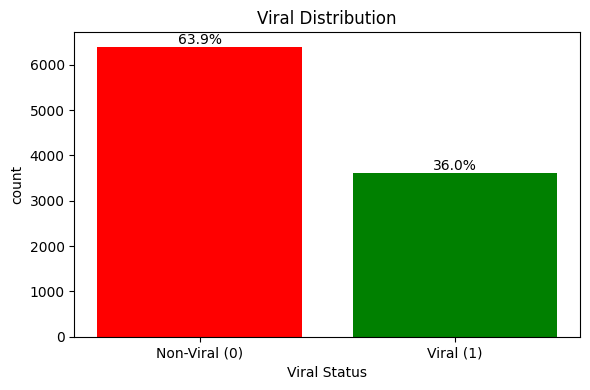

In [8]:
plt.figure(figsize=(6,4))
counts=df['viral'].value_counts().sort_index()
percentages=counts/counts.sum()*100
plt.bar(counts.index,counts.values,color=['red','green'])
plt.title('Viral Distribution')
plt.xlabel('Viral Status')
plt.ylabel('count')
plt.xticks([0,1],['Non-Viral (0)','Viral (1)'])
for x, y, p in zip(counts.index, counts.values, percentages):
    plt.text(x, y, f'{p:.1f}%', ha='center', va='bottom')
plt.tight_layout()
plt.show()

**Insight**: Non-viral tracks dominate at 63.9%, while only 36.0% are viral, indicating a moderate class imbalance.

### 2. Distribution of 'streams' 

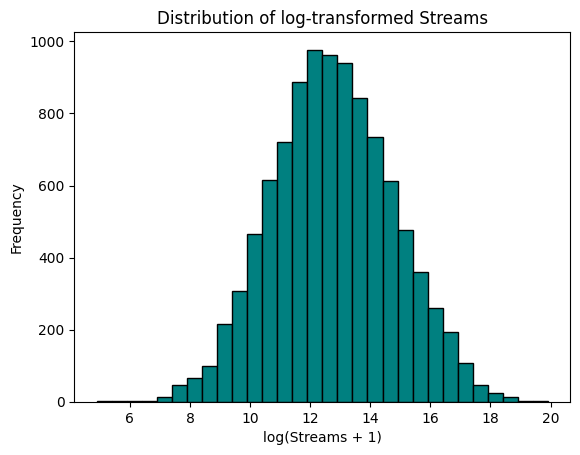

In [9]:
plt.hist(np.log1p(df["streams"]), bins=30, color="teal", edgecolor="black")
plt.xlabel("log(Streams + 1)")
plt.ylabel("Frequency")
plt.title("Distribution of log-transformed Streams")
plt.show()

**Streams Distribution:** The `streams` Streams are heavily right-skewed, but become approximately normal after a log transform.

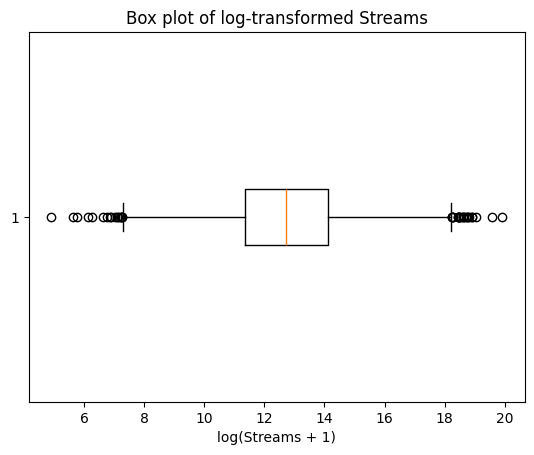

In [10]:
# Outliers visulization for 'Streams':

plt.boxplot(np.log1p(df["streams"]), vert=False)
plt.xlabel("log(Streams + 1)")
plt.title("Box plot of log-transformed Streams")
plt.show()

## Statistical Analysis

In [11]:
num_cols = df.select_dtypes(include="number").columns

summary = pd.DataFrame({
    "mean":   df[num_cols].mean(),
    "median": df[num_cols].median(),
    "std":    df[num_cols].std(),
    "min":    df[num_cols].min(),
    "max":    df[num_cols].max(),
    "skew":   df[num_cols].skew(),
    "kurt":   df[num_cols].kurt(),
}).round(2)

pd.options.display.float_format = "{:,.2f}".format
print(summary)

                         mean     median          std      min            max  \
release_year         2,017.50   2,018.00         4.61 2,010.00       2,025.00   
duration_sec           208.78     209.00        49.97    60.00         433.00   
danceability             0.61       0.62         0.19     0.00           1.00   
energy                   0.65       0.67         0.19     0.00           1.00   
valence                  0.58       0.58         0.18     0.00           1.00   
tempo_bpm              110.98     111.30        19.02    50.00         177.80   
acousticness             0.30       0.24         0.26     0.00           1.00   
instrumentalness         0.18       0.15         0.16     0.00           0.93   
speechiness              0.09       0.08         0.07     0.00           0.38   
liveness                 0.18       0.18         0.11     0.00           0.62   
loudness_db             -7.98      -7.98         2.98   -18.74           0.00   
streams          2,415,684.8

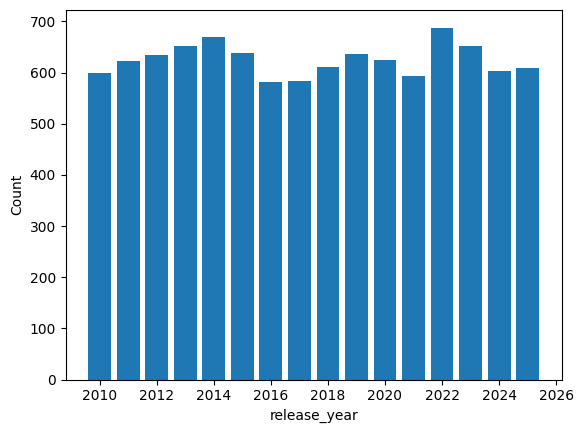

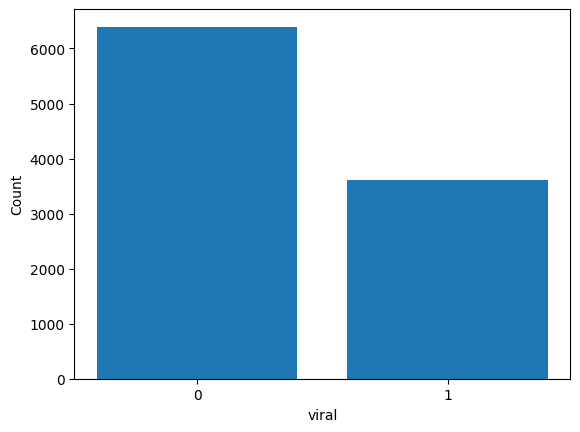

In [12]:
yr = df["release_year"].value_counts().sort_index()
plt.bar(yr.index, yr.values)
plt.xlabel("release_year")
plt.ylabel("Count")
plt.show()

v = df["viral"].value_counts().sort_index()
plt.bar(v.index.astype(str), v.values)
plt.xlabel("viral")
plt.ylabel("Count")
plt.show()

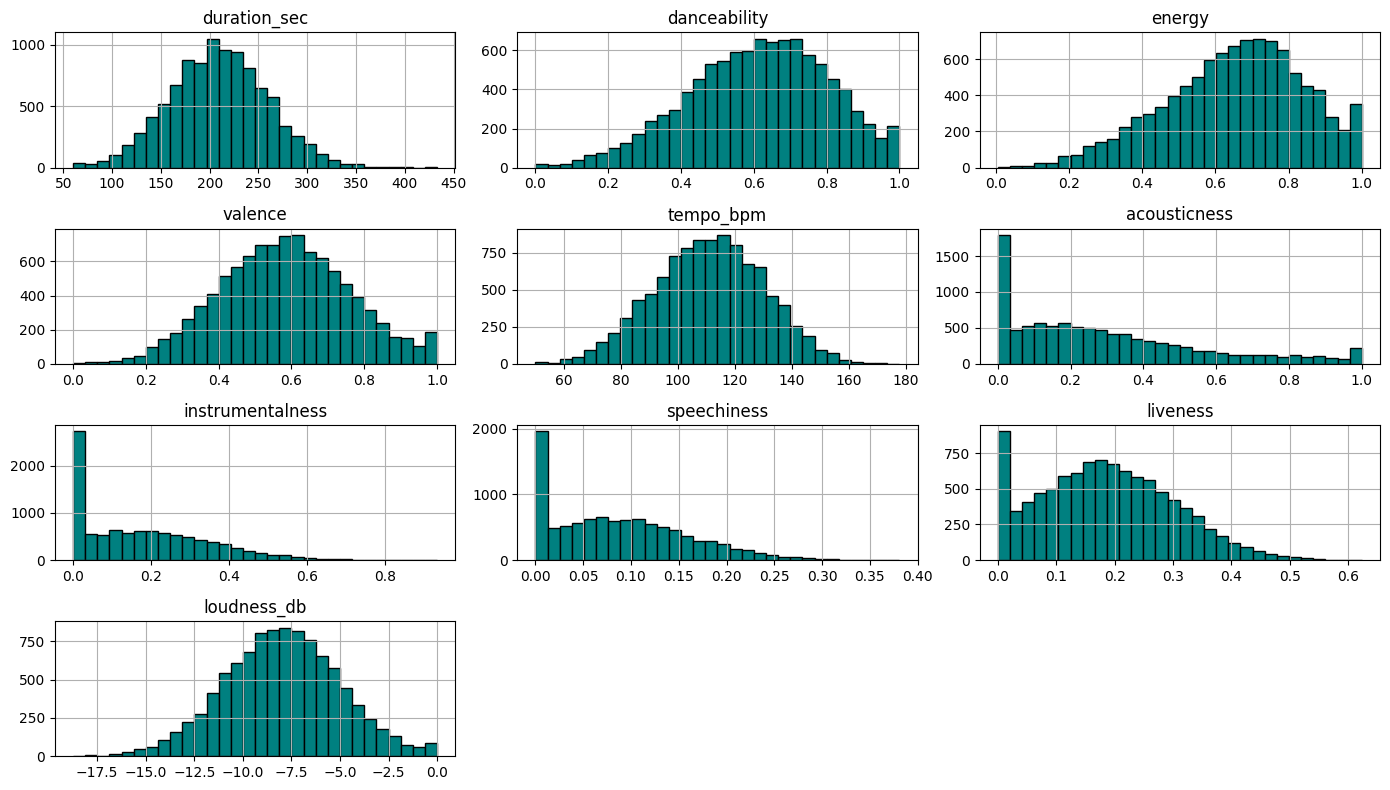

In [13]:
cols = ["duration_sec", "danceability", "energy", "valence", "tempo_bpm",
        "acousticness", "instrumentalness", "speechiness", "liveness", "loudness_db"]

df[cols].hist(bins=30, figsize=(14, 8), edgecolor="black",color='teal')
plt.tight_layout()
plt.show()

## Univariate Analysis: Summary

- **`streams`:** extremely right-skewed (skew 18.4). A log transform gives a near-normal shape, so it will be used for regression.
- **`viral`:** a mild imbalance.
- **`release_year`:** roughly uniform across 2010 to 2025.
- **Near-normal:** `duration_sec`, `tempo_bpm`, `loudness_db`, `valence`.
- **Mild left skew:** `danceability`, `energy`.
- **Right skew:** `acousticness`, `instrumentalness`, `speechiness`.
- **Data quality:** no missing values, but several features show spikes at their bounds (0 or 1).

## Correlation Matrix

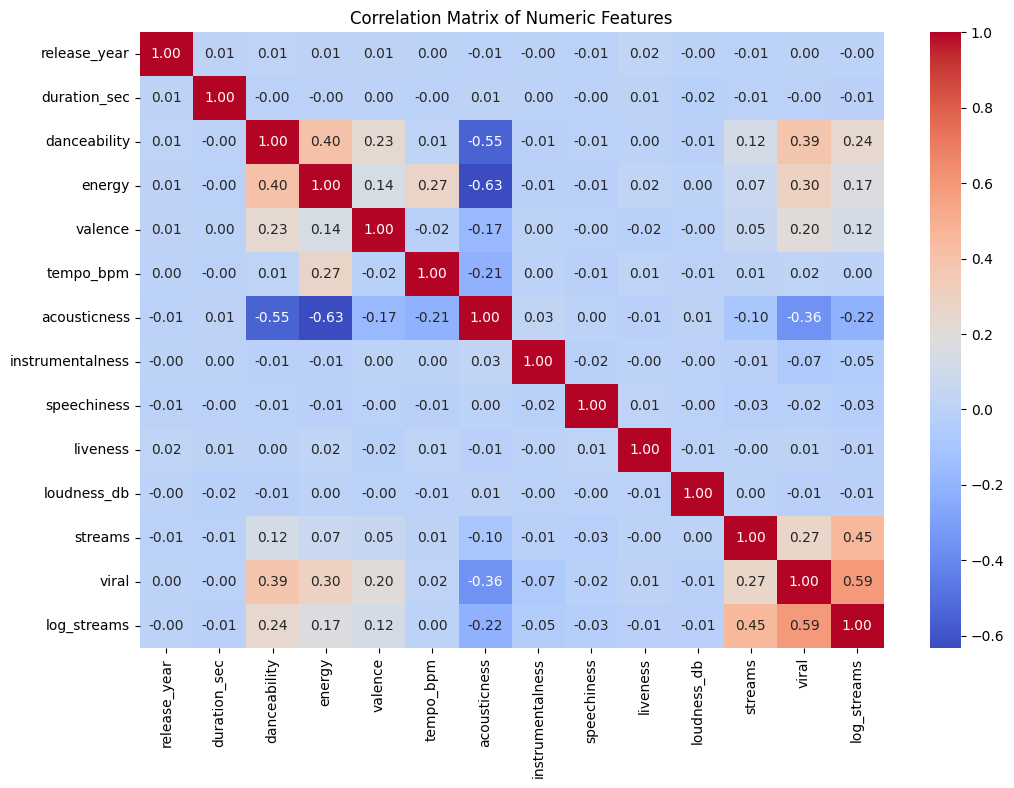

In [14]:
df["log_streams"] = np.log1p(df["streams"])
corr = df.select_dtypes(include='number').corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numeric Features')
plt.show()

## Correlation Analysis

- `viral` and `log_streams` correlate at 0.59: related but not identical, so no direct leakage.
- most strongly associated with both targets: `danceability` (+), `acousticness` (-), `energy` (+), `valence` (+).
- `release_year`, `duration_sec`, `tempo_bpm`, `liveness`, `loudness_db` show no linear relationship with either target.
- Highest feature-feature correlation: `acousticness` vs `energy` (-0.63), so no severe multicollinearity.
- Raw `streams` correlates weaker than `log_streams`, confirming the log transform.
- Categorical columns (`genre`, `artist`) are still to be analyzed.

## Categorical Features Analysis

In [15]:
for c in ["track_id", "track_name", "artist", "genre"]:
    print(c, "| unique:", df[c].nunique())

print(df["genre"].value_counts())

track_id | unique: 10000
track_name | unique: 10000
artist | unique: 1987
genre | unique: 10
genre
Rock          1084
Hip-Hop       1052
Latin         1030
Pop           1002
Indie          993
Electronic     991
Classical      991
Jazz           965
R&B            950
Country        942
Name: count, dtype: int64


In [16]:
df["log_streams"] = np.log1p(df["streams"])

print(df.groupby("genre")[["log_streams", "viral"]].mean().round(2))

            log_streams  viral
genre                         
Classical         11.91   0.01
Country           12.44   0.24
Electronic        13.14   0.51
Hip-Hop           13.45   0.61
Indie             12.24   0.14
Jazz              11.96   0.06
Latin             13.58   0.65
Pop               13.40   0.62
R&B               12.81   0.41
Rock              12.53   0.33


## Categorical Analysis Summary

- `track_id` and `track_name` are unique per row (10,000), so they carry no information and are dropped.
- `genre` has 10 balanced categories (about 940 to 1,080 songs each).
- Genre is strongly associated with both targets: viral rate ranges from 1% (Classical) to 65% (Latin), and typical streams differ by about 5x between the top and bottom genres.
- High viral/streams: Latin, Pop, Hip-Hop, Electronic. Low: Classical, Jazz, Indie.
- `artist` has 1,987 unique values (high cardinality) and needs special handling.

## Artist Analysis

In [17]:
print(df["artist"].nunique())
print(df["artist"].value_counts().describe())
print(df["artist"].value_counts().head(10))

1987
count   1,987.00
mean        5.03
std         2.18
min         1.00
25%         3.00
50%         5.00
75%         6.00
max        15.00
Name: count, dtype: float64
artist
Artist_0796    15
Artist_0552    13
Artist_0612    13
Artist_0164    13
Artist_1052    12
Artist_0379    12
Artist_1687    12
Artist_1950    12
Artist_0535    12
Artist_0493    12
Name: count, dtype: int64


# Post-EDA: Data Preparation for Modeling

In [18]:
# Preparing for regression model

df_reg=df.copy()
df_reg=df_reg.drop(columns=["track_id", "track_name", "artist", "streams", "viral"])

X=df_reg.drop(columns="log_streams")
y=df_reg["log_streams"]

print(X.columns.tolist())

['genre', 'release_year', 'duration_sec', 'danceability', 'energy', 'valence', 'tempo_bpm', 'acousticness', 'instrumentalness', 'speechiness', 'liveness', 'loudness_db']


In [19]:
# Encode genre

X_enc = pd.get_dummies(X, columns=['genre'],drop_first=True, dtype=int)
print(X_enc.shape)
X_enc.head()

(10000, 20)


,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,genre_Country,genre_Electronic,genre_Hip-Hop,genre_Indie,genre_Jazz,genre_Latin,genre_Pop,genre_R&B,genre_Rock
0,2013,237,0.76,0.70,0.75,140.80,0.12,0.10,0.21,0.27,-9.41,0,0,0,0,0,0,1,0,0
1,2018,239,0.44,0.93,0.67,105.10,0.02,0.00,0.02,0.00,-9.89,0,1,0,0,0,0,0,0,0
2,2014,148,0.64,0.72,0.46,90.60,0.01,0.52,0.08,0.05,-5.53,0,0,1,0,0,0,0,0,0
3,2012,216,0.33,0.46,0.30,71.30,0.97,0.04,0.00,0.07,-11.39,0,0,0,0,0,0,0,0,0
4,2011,277,0.60,0.68,0.70,132.60,0.08,0.11,0.00,0.04,-5.56,0,0,0,0,0,0,1,0,0


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_enc, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(8000, 20) (2000, 20)


In [21]:
# Scaling

from sklearn.preprocessing import StandardScaler

num_cols = ["release_year", "duration_sec", "danceability", "energy", "valence",
            "tempo_bpm", "acousticness", "instrumentalness", "speechiness",
            "liveness", "loudness_db"]

scaler=StandardScaler()

X_train[num_cols]=scaler.fit_transform(X_train[num_cols])
X_test[num_cols]=scaler.transform(X_test[num_cols])

In [22]:
# Fit the model

from sklearn.linear_model import LinearRegression

model=LinearRegression()
model.fit(X_train,y_train)

LinearRegression()

In [23]:
# Evaluate

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pred = model.predict(X_test)
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
print("MAE: ", mean_absolute_error(y_test, pred))
print("R2:  ", r2_score(y_test, pred))

RMSE: 1.9218125596461701
MAE:  1.5327363543018842
R2:   0.09217043964440907


## Baseline: Linear Regression (target: `log_streams`)

- **Setup:** `genre` one-hot encoded, 11 numeric features standardized, 80/20 split.
- **Results (log scale):** R² = 0.09, RMSE = 1.92, MAE = 1.53.
- **Interpretation:** genre and audio features explain only about 9% of the variance in streams. This matches the EDA, where feature correlations with `log_streams` were weak (max |r| = 0.24).


## Optimizing the Baseline: Ridge Regression

In [24]:
from sklearn.linear_model import RidgeCV
from sklearn.metrics import r2_score

model=RidgeCV(alphas=[0.1,1,10,100])
model.fit(X_train,y_train)

print("Best alpha:",model.alpha_)
print("R2:",r2_score(y_test,model.predict(X_test)))

Best alpha: 10.0
R2: 0.09302490733732038


### Ridge Regression (RidgeCV)

- Best alpha = 10; R² = 0.093 (vs. 0.092 for plain Linear Regression).
- Regularization gives almost no improvement, so the linear model is not overfitting. Its performance is limited by the information in the features.
- Next: Random Forest to check for non-linear patterns.